# 02 — Rede: fundamentos e travessia (semanas 2 e 3)

Este notebook constrói o **digrafo da malha doméstica** a partir de
`resultados/base_rotas_2025.csv` (gerado pelo `01_dados.ipynb`) e aplica as ferramentas
da semana 2 (modelagem, densidade, grau, distribuição de grau, matriz de adjacência) e
da semana 3 (BFS, grau de entrada e de saída, núcleo e periferia, amostragem).

**Modelagem (fixada no `01_dados`):** nó = aeródromo (sigla ICAO); aresta dirigida =
rota doméstica origem → destino; peso = `DECOLAGENS` (oferta) e `PASSAGEIROS PAGOS`
(demanda); fica de fora a malha internacional, voo com escala, frequência por dia,
aeronave, preço, carga e capacidade.


In [1]:

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

RAIZ = Path.cwd().resolve()
while not (RAIZ / "data" / "2025.csv").exists():
    if RAIZ == RAIZ.parent:
        raise FileNotFoundError("rode o notebook de dentro do repositório do projeto")
    RAIZ = RAIZ.parent

sys.path.insert(0, str(RAIZ / "src"))
import malha as M  # noqa: E402

FIGURAS = RAIZ / "figuras"
RESULTADOS = RAIZ / "resultados"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})
regioes = {"NORTE": "#2ca02c", "NORDESTE": "#ff7f0e", "CENTRO-OESTE": "#8c564b",
           "SUDESTE": "#1f77b4", "SUL": "#d62728"}
print("raiz do projeto:", RAIZ.name)


raiz do projeto: air-traffic-brazil


## 1. Construção da rede e cartão de identidade

A primeira leitura é a escala: quantos nós e arestas, e quão densa é a malha.
Densidade alta costuma ser rede pequena; o teste de sanidade é conferir o grau médio.

In [2]:

rotas = pd.read_csv(RESULTADOS / "base_rotas_2025.csv")
g = M.construir_digrafo(rotas)
h = M.grafo_nao_dirigido(g)  # projeção não dirigida (para triângulos, núcleos, pontes)

metricas = M.metricas_basicas(g)
pd.Series(metricas).to_csv(RESULTADOS / "metricas_basicas.csv", header=["valor"])
print(f"digrafo: {metricas['nos']} nós, {metricas['arestas']} arestas dirigidas")
print(f"densidade: {metricas['densidade']:.5f} | grau médio (total): {metricas['grau_medio']:.2f}")
print(f"grau máximo: {metricas['grau_maximo']} | mínimo: {metricas['grau_minimo']}")
print(f"projeção não dirigida: {h.number_of_nodes()} nós, {h.number_of_edges()} arestas simples")
arestas_reciprocas = sum(1 for u, v in g.edges() if g.has_edge(v, u))
print(f"pares com rota nas duas direções: {arestas_reciprocas / 2:.0f} de {h.number_of_edges()} "
      f"({100 * arestas_reciprocas / 2 / h.number_of_edges():.1f}%)")


digrafo: 176 nós, 1660 arestas dirigidas
densidade: 0.05390 | grau médio (total): 18.86
grau máximo: 181 | mínimo: 1
projeção não dirigida: 176 nós, 987 arestas simples
pares com rota nas duas direções: 673 de 987 (68.2%)


A malha é **esparsa** (densidade 0,054 — para 176 nós, o teto seria 30.800 rotas dirigidas;
existem 1.660) e o grau médio (18,9) está longe do máximo (181, em Campinas). Média e
máximo a uma ordem de grandeza de distância já anunciam cauda longa.

A reciprocidade confirma a escolha de grafo dirigido: dos 987 pares ligados, 673 (68%)
têm rota nos dois sentidos e **314 pares têm rota em um sentido só** — somar as direções
apagaria essa assimetria. O caso-limite do grau mínimo aparece aqui: `SBBP` (Bragança
Paulista) tem uma única "rota", `SBBP → SBSJ` com 1 decolagem e 0 passageiro pago no ano
— é decolagem de posicionamento, não ligação comercial (volta como artefato na análise).

In [3]:

graus = M.tabela_graus(g)
graus.to_csv(RESULTADOS / "graus.csv", index=False)
graus.head(10)[["icao", "nome", "uf", "grau_entrada", "grau_saida", "grau_total", "passageiros_total"]]


,icao,nome,uf,grau_entrada,grau_saida,grau_total,passageiros_total
0,SBGR,GUARULHOS,SP,67,67,134,29872406.0
1,SBSP,SÃO PAULO,SP,57,54,111,24043265.0
2,SBBR,BRASÍLIA,DF,43,48,91,15390238.0
3,SBCF,CONFINS,MG,81,75,156,12339499.0
4,SBGL,RIO DE JANEIRO,RJ,50,45,95,11928249.0
5,SBKP,CAMPINAS,SP,92,89,181,11654910.0
6,SBRF,RECIFE,PE,53,55,108,9242285.0
7,SBSV,SALVADOR,BA,37,39,76,7304233.0
8,SBPA,PORTO ALEGRE,RS,31,30,61,6928031.0
9,SBRJ,RIO DE JANEIRO,RJ,13,19,32,6046310.0


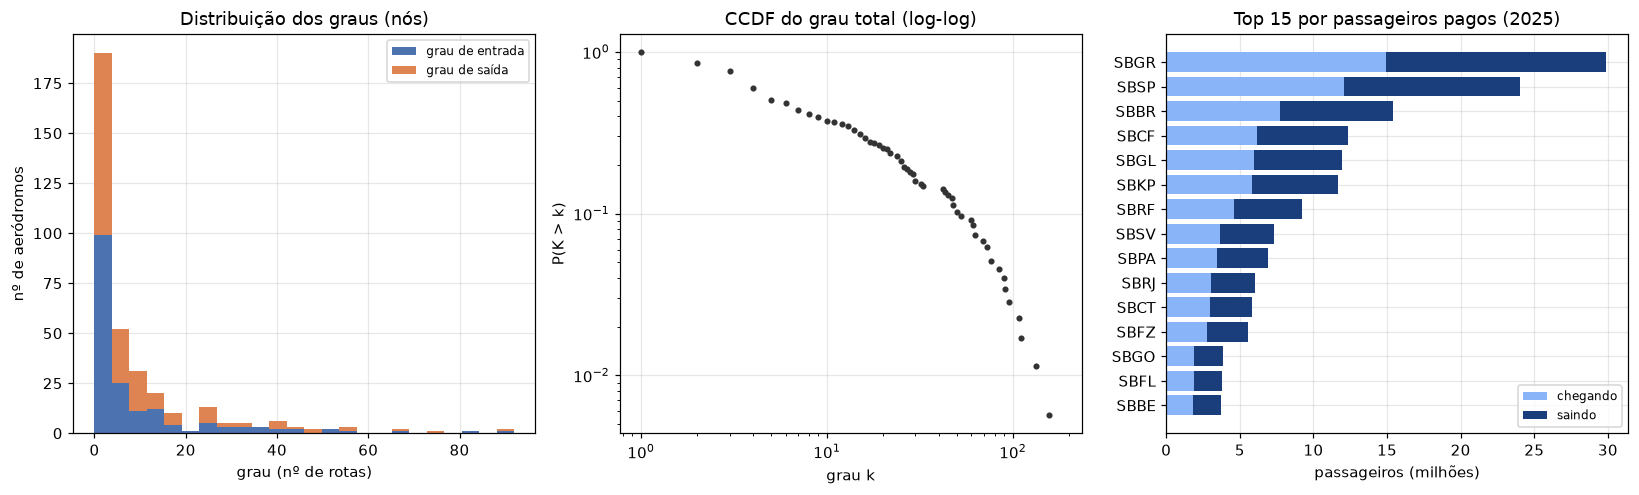

grau total mediano: 6.0
aeródromos com grau total <= 4: 71
menor grau: SBBP 1


In [4]:

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.6))

eixos[0].hist([graus.grau_entrada, graus.grau_saida], bins=24, stacked=True,
              label=["grau de entrada", "grau de saída"], color=["#4c72b0", "#dd8452"])
eixos[0].set_title("Distribuição dos graus (nós)")
eixos[0].set_xlabel("grau (nº de rotas)")
eixos[0].set_ylabel("nº de aeródromos")
eixos[0].legend(fontsize=8)

x_ccdf, y_ccdf = M.ccdf(graus.grau_total)
eixos[1].loglog(x_ccdf, y_ccdf, marker="o", markersize=3, linestyle="none", color="#333333")
eixos[1].set_title("CCDF do grau total (log-log)")
eixos[1].set_xlabel("grau k")
eixos[1].set_ylabel("P(K > k)")

top15 = graus.head(15).iloc[::-1]
eixos[2].barh(top15.icao, top15.passageiros_entrada / 1e6, label="chegando", color="#8ab4f8")
eixos[2].barh(top15.icao, top15.passageiros_saida / 1e6, left=top15.passageiros_entrada / 1e6,
              label="saindo", color="#1a3d7c")
eixos[2].set_title("Top 15 por passageiros pagos (2025)")
eixos[2].set_xlabel("passageiros (milhões)")
eixos[2].legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIGURAS / "02_graus_e_hubs.png", bbox_inches="tight")
plt.show()

print("grau total mediano:", graus.grau_total.median())
print("aeródromos com grau total <= 4:", (graus.grau_total <= 4).sum())
print("menor grau:", graus.icao[graus.grau_total.idxmin()], graus.grau_total.min())


A distribuição tem **cauda longa**: poucos aeródromos concentram centenas de conexões
(SBKP 181, SBCF 156, SBGR 134 de grau total) e a mediana é 6 — 71 dos 176 aeródromos
(40%) têm grau total ≤ 4. Consequência prática: a média (18,9) não descreve aeródromo
nenhum; qualquer leitura por média precisa vir com mediana e cauda. É essa forma que
autoriza falar em "hub" — a medida de hub depende da cauda, não do grau médio.

Grau e volume contam coisas diferentes. SBKP lidera em **grau** (181 rotas) mas é o 6º
em **passageiros** (11,7 mi); SBGR lidera em passageiros (29,9 mi) com grau 134. O caso
extremo é SBEG (Manaus): grau 90 e só 3,0 mi de passageiros — é um hub regional de
**rotas finas** (muitos destinos amazônicos de baixo volume). O ranking por grau
descreveria a malha como "Campinas no centro"; o ranking por volume diz "São Paulo no
centro". Os dois estão certos para perguntas diferentes — a nossa (contingência) precisa
dos dois: grau para alcance alternativo, volume para impacto.

## 2. Matriz de adjacência

A matriz mostra a topologia inteira dos 40 aeródromos mais conectados. A entrada
(a linha i, coluna j) é o peso da rota; na escala log para o volume não esmagar o resto.

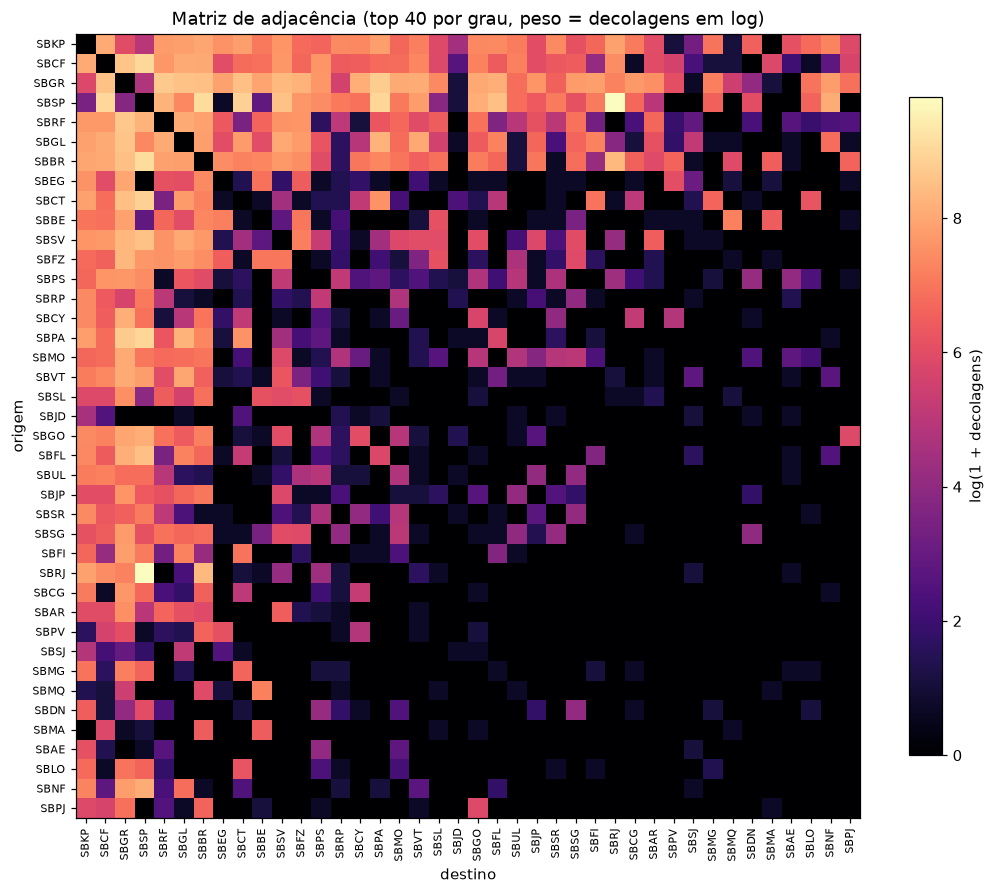

In [5]:

top40 = list(graus.sort_values("grau_total", ascending=False).head(40).icao)
A = M.matriz_adjacencia(g, top40)

fig, eixo = plt.subplots(figsize=(9.8, 8.6))
im = eixo.imshow(np.log1p(A), cmap="magma")
eixo.set_xticks(range(len(top40)), top40, rotation=90, fontsize=7)
eixo.set_yticks(range(len(top40)), top40, fontsize=7)
eixo.set_xlabel("destino")
eixo.set_ylabel("origem")
eixo.set_title("Matriz de adjacência (top 40 por grau, peso = decolagens em log)")
fig.colorbar(im, ax=eixo, shrink=0.75, label="log(1 + decolagens)")
eixo.grid(False)
fig.tight_layout()
fig.savefig(FIGURAS / "03_matriz_adjacencia.png", bbox_inches="tight")
plt.show()


A matriz é quase simétrica (rota de volta existe) mas com intensidades diferentes, e
concentra massa em poucas linhas/colunas — a "cruz" de São Paulo (SBSP, SBGR, SBCF)
e Brasília. Fora desse bloco, as células são cinzas-escuras: rotas regionais de pouco
volume entre a cauda longa.

## 3. A rede no mapa

Coordenadas: OurAirports (dados públicos), arquivo `data/aerodromos_coordenadas.csv`
gerado por `scripts/gerar_coordenadas.py`. Tamanho do nó = grau total; cor = região;
espessura da linha = volume da rota (soma dos dois sentidos).

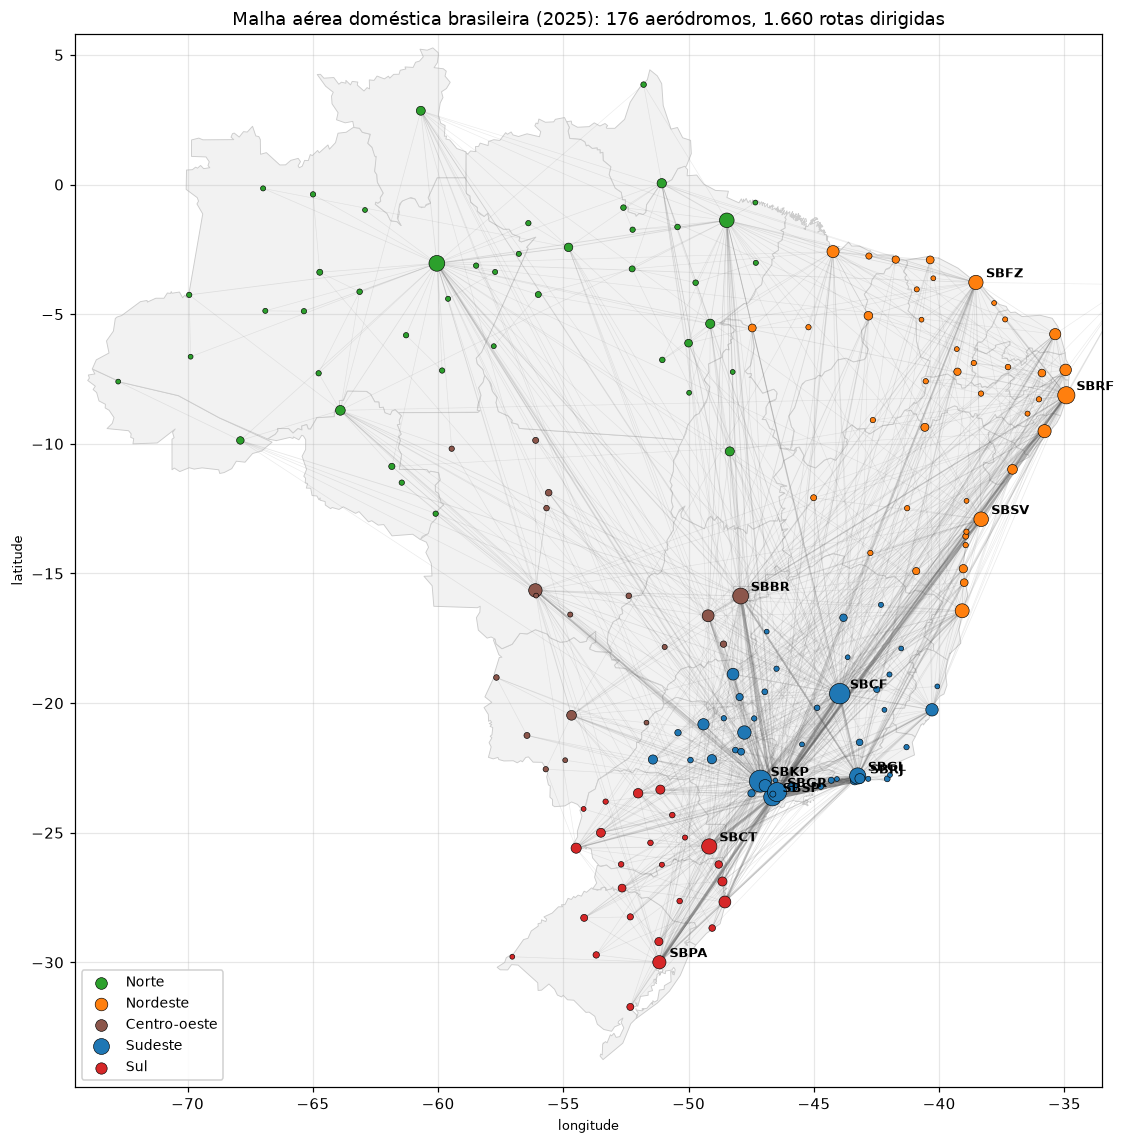

nós por região: {'SUDESTE': 47, 'NORTE': 44, 'NORDESTE': 42, 'SUL': 25, 'CENTRO-OESTE': 18}


In [6]:

pos = M.posicoes(g)

fig, eixo = plt.subplots(figsize=(11, 10.5))
M.fundo_mapa(eixo)

peso_max = max(d["decolagens"] for _, _, d in h.edges(data=True))
for u, v, d in h.edges(data=True):
    eixo.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]],
              color="#555555", alpha=0.12 + 0.5 * d["decolagens"] / peso_max,
              linewidth=0.4 + 3.4 * d["decolagens"] / peso_max, zorder=1)

for regiao, cor in regioes.items():
    nos_regiao = [n for n in g if g.nodes[n]["regiao"] == regiao]
    eixo.scatter([pos[n][0] for n in nos_regiao], [pos[n][1] for n in nos_regiao],
                 s=[8 + 1.1 * g.degree(n) for n in nos_regiao], color=cor, edgecolor="black",
                 linewidth=0.4, label=regiao.capitalize(), zorder=3)

for n in graus.head(12).icao:
    eixo.annotate(n, (pos[n][0] + 0.4, pos[n][1] + 0.2), fontsize=8.5, fontweight="bold", zorder=4)

eixo.set_title("Malha aérea doméstica brasileira (2025): 176 aeródromos, 1.660 rotas dirigidas")
eixo.set_xlabel("longitude"); eixo.set_ylabel("latitude")
eixo.set_xlim(-74.5, -33.5); eixo.set_ylim(-34.8, 5.8); eixo.set_aspect(1.035)
eixo.legend(loc="lower left", fontsize=9, framealpha=0.9)
fig.tight_layout()
fig.savefig(FIGURAS / "04_mapa_malha.png", bbox_inches="tight")
plt.show()

por_regiao_nos = g.nodes(data=True)
contagem = {}
for n, dados in por_regiao_nos:
    contagem[dados["regiao"]] = contagem.get(dados["regiao"], 0) + 1
print("nós por região:", dict(sorted(contagem.items(), key=lambda x: -x[1])))


O mapa mostra a assimetria do país na malha: o Sudeste concentra nós e linhas; o Norte
tem muitos aeródromos com poucas rotas e um hub regional forte (SBEG, Manaus); o
Nordeste se organiza em torno de SBRF (Recife), SBSV (Salvador) e SBFZ (Fortaleza).
A espessura das linhas denuncia o eixo SP–RJ–BSB como o "tronco" de volume.

## 4. Travessia: BFS e camadas (semana 3)

BFS responde "quantos saltos até cada aeródromo", partindo de SBGR. A pergunta de
contingência é: quão longe fica o aeródromo mais distante?

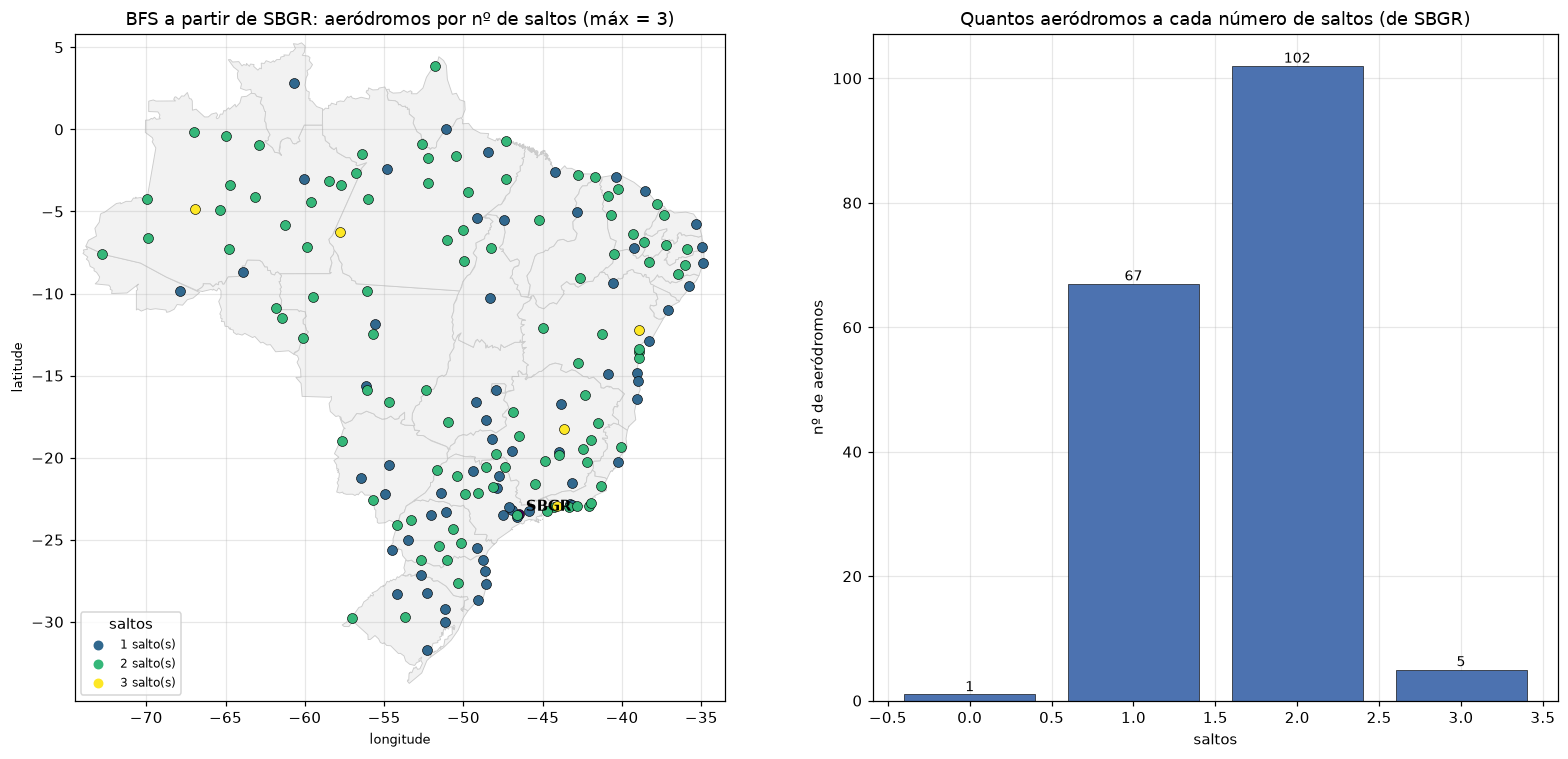

alcançáveis a partir de SBGR: 175 de 176
distância média de SBGR: 1.63 saltos | pior caso: 3
em até 2 saltos: 170 aeródromos (97%)


In [7]:

niveis = M.camadas_bfs(g, "SBGR")
por_nivel = pd.Series(niveis).value_counts().sort_index()

fig, eixos = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.25, 1]})

M.fundo_mapa(eixos[0])
cmap = plt.get_cmap("viridis")
nivel_max = max(niveis.values())
for n, nivel in niveis.items():
    eixos[0].scatter(*pos[n], color=cmap(nivel / nivel_max), s=42, edgecolor="black", linewidth=0.4, zorder=3)
eixos[0].annotate("SBGR", (pos["SBGR"][0] + 0.4, pos["SBGR"][1] + 0.2), fontweight="bold")
eixos[0].set_xlim(-74.5, -33.5); eixos[0].set_ylim(-34.8, 5.8); eixos[0].set_aspect(1.035)
eixos[0].set_title(f"BFS a partir de SBGR: aeródromos por nº de saltos (máx = {nivel_max})")
eixos[0].set_xlabel("longitude"); eixos[0].set_ylabel("latitude")
for nivel in range(1, nivel_max + 1):
    eixos[0].scatter([], [], color=cmap(nivel / nivel_max), label=f"{nivel} salto(s)", s=30)
eixos[0].legend(fontsize=8, loc="lower left", title="saltos")

eixos[1].bar(por_nivel.index, por_nivel.values, color="#4c72b0", edgecolor="black", linewidth=0.4)
for nivel, valor in por_nivel.items():
    eixos[1].annotate(str(valor), (nivel, valor), ha="center", va="bottom", fontsize=9)
eixos[1].set_title("Quantos aeródromos a cada número de saltos (de SBGR)")
eixos[1].set_xlabel("saltos"); eixos[1].set_ylabel("nº de aeródromos")
fig.tight_layout()
fig.savefig(FIGURAS / "05_bfs_camadas.png", bbox_inches="tight")
plt.show()

print(f"alcançáveis a partir de SBGR: {len(niveis)} de {g.number_of_nodes()}")
print(f"distância média de SBGR: {np.mean(list(niveis.values())):.2f} saltos | pior caso: {nivel_max}")
print(f"em até 2 saltos: {sum(v <= 2 for v in niveis.values())} aeródromos "
      f"({100 * sum(v <= 2 for v in niveis.values()) / g.number_of_nodes():.0f}%)")


A malha é de **mundo pequeno**: partindo de SBGR, 170 dos 176 aeródromos (97%) estão a
até 2 saltos, o mais distante está a 3, e a distância média é 1,63 salto. O único
aeródromo não alcançado é `SBBP` — a decolagem única de posicionamento que já apareceu;
para alcançá-lo seria preciso voar primeiro para ele (grau de entrada 0).

**Mas** (limite do conceito): distância média baixa não significa resiliência — o caminho
pode passar por um único nó obrigatório. É exatamente o que a análise de falha, no
`03_analise`, mede.

## 5. Efeito da amostragem por bola de neve (semana 3)

Se a malha fosse coletada por vizinhança (não existe o grafo inteiro, como na web),
o que se veria? Simulamos a coleta por BFS a partir de duas sementes e medimos como
cada métrica se distorce quando só se enxerga até a camada k.

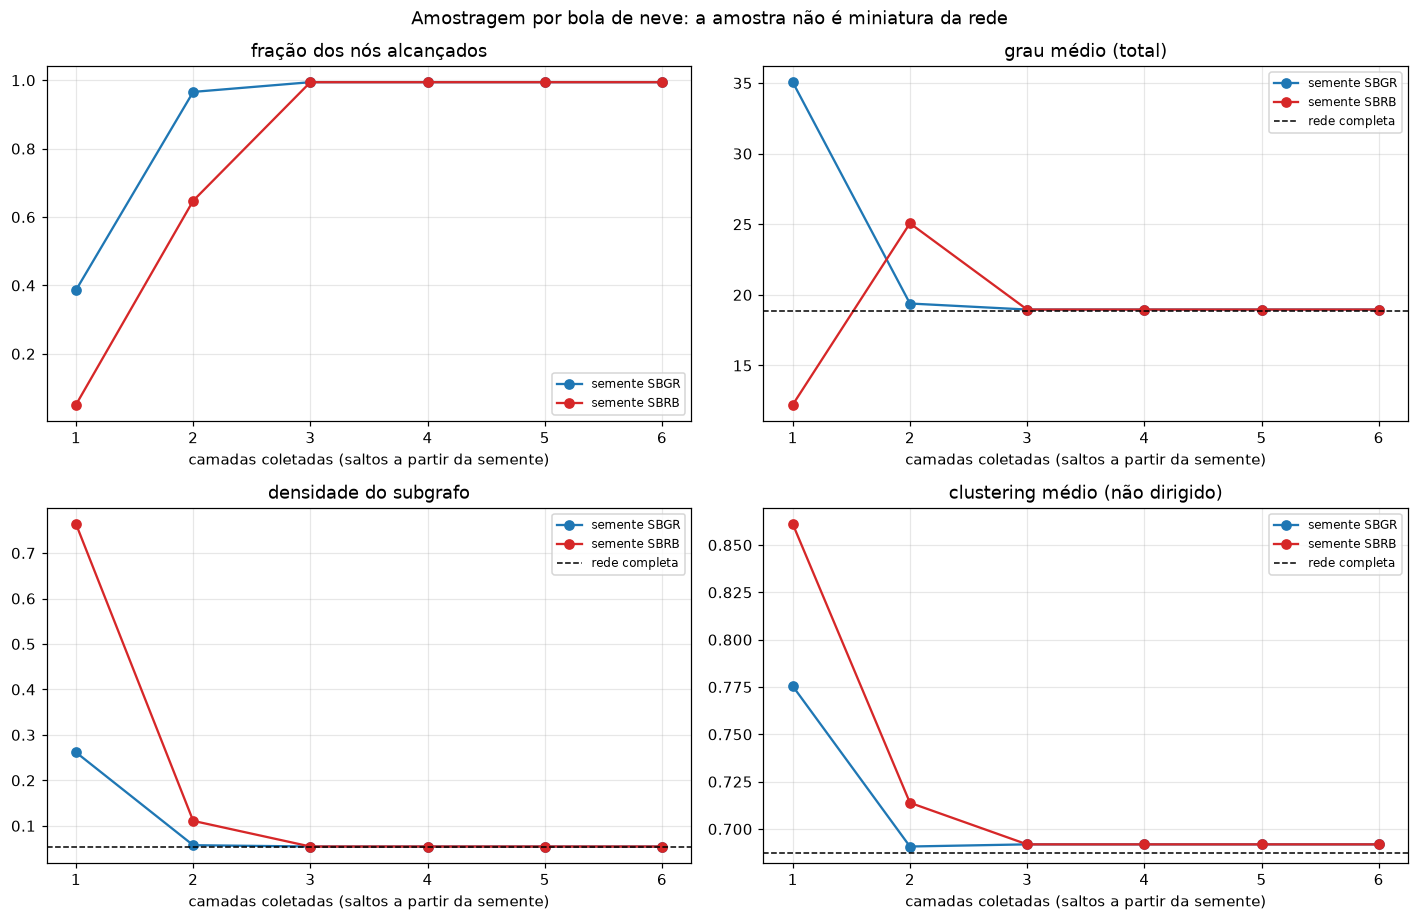

,camada,nos,arestas,fracao_nos,densidade,grau_medio,clustering_medio,semente
0,1,68,1192,0.3864,0.2616,35.0588,0.7755,SBGR
1,2,170,1648,0.9659,0.0574,19.3882,0.6908,SBGR
2,3,175,1659,0.9943,0.0545,18.9600,0.6919,SBGR
3,4,175,1659,0.9943,0.0545,18.9600,0.6919,SBGR
4,5,175,1659,0.9943,0.0545,18.9600,0.6919,SBGR
5,6,175,1659,0.9943,0.0545,18.9600,0.6919,SBGR
6,1,9,55,0.0511,0.7639,12.2222,0.8611,SBRB
7,2,114,1429,0.6477,0.1109,25.0702,0.7139,SBRB
8,3,175,1659,0.9943,0.0545,18.9600,0.6919,SBRB
9,4,175,1659,0.9943,0.0545,18.9600,0.6919,SBRB


In [8]:

amostras = []
for semente in ["SBGR", "SBRB"]:
    t = M.experimento_snowball(g, semente, camadas_max=6)
    t["semente"] = semente
    amostras.append(t)
amostragem = pd.concat(amostras, ignore_index=True)
amostragem.to_csv(RESULTADOS / "amostragem_snowball.csv", index=False)

completa = {
    "fracao_nos": 1.0,
    "densidade": M.metricas_basicas(g)["densidade"],
    "grau_medio": M.metricas_basicas(g)["grau_medio"],
    "clustering_medio": nx.average_clustering(h),
}
metricas_painel = [("fracao_nos", "fração dos nós alcançados", 1.0),
                   ("grau_medio", "grau médio (total)", None),
                   ("densidade", "densidade do subgrafo", None),
                   ("clustering_medio", "clustering médio (não dirigido)", None)]

fig, eixos = plt.subplots(2, 2, figsize=(13, 8.5))
for eixo, (coluna, titulo, escala) in zip(eixos.ravel(), metricas_painel):
    for semente, cor in [("SBGR", "#1f77b4"), ("SBRB", "#d62728")]:
        dados = amostragem[amostragem.semente == semente]
        eixo.plot(dados.camada, dados[coluna], marker="o", label=f"semente {semente}", color=cor)
    if not escala:
        eixo.axhline(completa[coluna], color="black", linestyle="--", linewidth=1,
                     label="rede completa")
    eixo.set_title(titulo)
    eixo.set_xlabel("camadas coletadas (saltos a partir da semente)")
    eixo.legend(fontsize=8)
fig.suptitle("Amostragem por bola de neve: a amostra não é miniatura da rede", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURAS / "06_amostragem_snowball.png", bbox_inches="tight")
plt.show()

amostragem.round(4)


O painel mostra as duas distorções clássicas da coleta por vizinhança, e que o **viés
depende da semente**:

- **Primeira camada parece outro mundo**: 68 nós (39% da rede) em volta de SBGR, com
  densidade 0,26 (5× a real) e clustering 0,78 — todo vizinho da semente é vizinho dela,
  então o subgrafo parece uma bolha coesa. Desde SBRB (Acre), a camada 1 tem só 9 nós.
- **Grau médio não tem viés único**: na camada 1 de SBGR fica em 35 (a semente e vizinhos
  ricos dominam — hubs entram cedo e são superestimados); na camada 2 de SBRB fica em 25;
  só depois converge para perto do real (18,9).
- **Saturação rápida**: para SBGR, a camada 2 já cobre 96,6% dos nós; o que falta nunca
  tem todos os vizinhos — os nós de fronteira aparecem sem os vizinhos de fora.

Moral para o projeto: o dado da ANAC é o grafo **completo** do recorte — não estamos
amostrando; mas se quiséssemos simular "radar de alcance limitado" (só enxergo quem está
a k saltos), toda métrica teria de vir com correção de fronteira e com a semente
declarada, porque a forma da amostra muda com ela.

## 6. Visualização com nxviz (semana 4, anunciada aqui)

Circos do subgrafo dos 30 aeródromos mais conectados, agrupado por região: cada setor é
uma região; o raio/ângulo organiza os nós, e os arcos mostram as rotas entre setores.

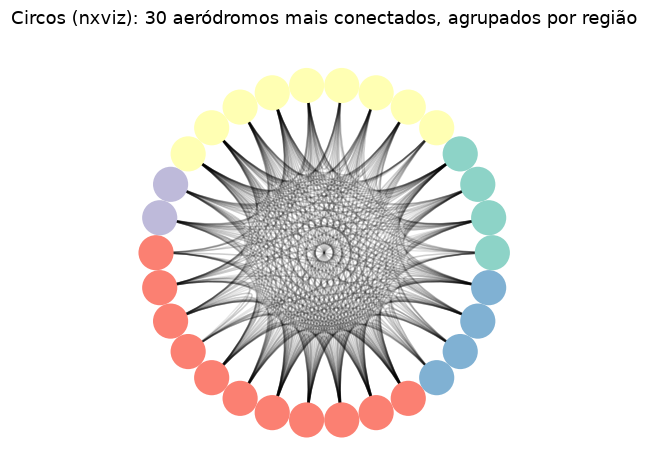

In [9]:

# nxviz (visualização do curso) — com o ajuste necessário para o matplotlib atual
import matplotlib.cm
if not hasattr(matplotlib.cm, "get_cmap"):
    matplotlib.cm.get_cmap = lambda nome, lut=None: matplotlib.colormaps[nome]
from nxviz import nodes as nv_nodes, edges as nv_edges  # noqa: E402
import nxviz as nv  # noqa: E402

top30 = list(graus.sort_values("grau_total", ascending=False).head(30).icao)
sub = g.subgraph(top30).copy()
nx.set_node_attributes(sub, {n: g.degree(n) for n in sub}, "grau_total")
nv.circos(sub, group_by="regiao", sort_by="grau_total",
          node_color_by="regiao", node_layout_func=nv_nodes.circos,
          edge_line_func=nv_edges.circos)
plt.title("Circos (nxviz): 30 aeródromos mais conectados, agrupados por região", y=1.04)
plt.savefig(FIGURAS / "07_circos_regioes.png", dpi=200, bbox_inches="tight")
plt.show()


## Síntese — semanas 2 e 3

- **Semana 2** — digrafo com atributos de nó e aresta; densidade (0,054, rede esparsa);
  grau e distribuição de grau (cauda longa: mediana 6 × máximo 181, 40% dos aeródromos
  com grau total ≤ 4); matriz de adjacência (massa concentrada nos hubs).
- **Semana 3** — BFS em camadas (mundo pequeno: 97% dos aeródromos a ≤ 2 saltos de SBGR);
  grau de entrada e de saída (só 68% dos pares têm as duas direções — o dirigido não é
  decorativo); núcleo e periferia (a cauda de grau 1–4 volta na decomposição em núcleos);
  amostragem por bola de neve (artefato de fronteira dependente da semente).

Segue em `03_analise.ipynb`: componentes, distâncias, centralidades, k-core, k-truss,
bipartido/Jaccard, esqueleto por limiar e análise de falha (semanas 4 a 6 + resposta).
